# ArtELingo CBM: Tuesday proof of concept

In ArtELingo, people look at a painting, pick the emotion it gives them and say why, in
English, Arabic or Chinese. We plan to model this with a concept bottleneck:
painting → visual concepts → emotion.

That plan rests on a few quiet assumptions. Language makes a difference to the emotion
people pick. The difference is tied to what is in the painting. And it is more than each
group simply favouring some labels. This notebook checks those assumptions before we
build on them. Each part asks one question, states a hypothesis, and compares the result
with what we would see if language made no difference at all.

Arabic and Chinese explanations in the examples come with English translations by
Claude Opus 5.5, marked (trans.). They are only there to help us read the examples; no
analysis uses them.

**To run:** `uv sync`, then `uv run jupyter lab` and Restart & Run All. The first run
downloads the images and embeds them; later runs reuse the files in `data/`.

Load the settings from `config.yaml` and print them, so every run shows what it used.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from artcbm import analysis, data, embed, plots, show
from artcbm.config import REPO_ROOT, load_config, resolve_device, set_seeds

cfg = load_config()
set_seeds(cfg.seed)
DEVICE = resolve_device(cfg.device)
LANGS, EMOS = list(cfg.data.languages), list(cfg.data.emotions)
plots.setup_style()
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", message="IProgress not found")  # plain progress bars

print((REPO_ROOT / "config.yaml").read_text())
print("device:", DEVICE)

seed: 42
device: auto                 # auto picks mps on Apple Silicon, else cpu

data:
  # ArtELingo-28 train CSV (no images); see notebook section 0 for where it comes from
  annotations_csv: data/raw/artelingo28_train_final.csv
  annotations_parquet: data/annotations.parquet
  # images fetched from wikiart.org by painting slug (only the kept paintings)
  images_dir: data/images
  languages: [english, arabic, chinese]   # exact strings in the CSV (lowercase)
  emotions: [amusement, awe, contentment, excitement, anger, disgust, fear, sadness, something else]
  min_annotations_per_language: 5
  max_paintings: 8000        # cap on paintings kept; 843 pass the filter, so no-op for now

embedding:
  model: ViT-B-32-quickgelu   # the OpenAI weights were trained with QuickGELU
  pretrained: openai
  batch_size: 64
  cache_dir: data/embeddings

concepts:
  path: concepts/generic_v1.txt
  template: "a painting with {}"   # CLIP prompt; {} is replaced by each concept

analysis:
  n_permutatio

## 0. The data

We use the ArtELingo-28 annotations. Each row is one person's emotion label for one
WikiArt painting, with a short explanation. We keep the English, Arabic and Chinese
annotations, and only the paintings that have at least five in each language and whose
image we could download from wikiart.org. For each of those paintings we take exactly
five annotations per language, so every language sees every painting equally often.

Load and filter the annotations, download the images (only the first run does this),
balance, and count what is left.

In [2]:
ann = data.load_annotations(cfg)
kept = data.filter_paintings(
    ann, LANGS, cfg.data.min_annotations_per_language, cfg.data.max_paintings, cfg.seed
)
painting_images = kept.drop_duplicates("painting").set_index("painting")["image_name"]
missing = data.fetch_wikiart_images(painting_images, cfg.data.images_dir)
painting_images = painting_images[~painting_images.isin(missing["image_name"])]
kept = kept[kept["painting"].isin(painting_images.index)]

bal = data.balance_per_painting(kept, cfg.data.min_annotations_per_language, cfg.seed)
labels = data.label_array(bal, LANGS, EMOS)  # (paintings, languages, annotations)


def image_path(painting):
    return cfg.data.images_dir / painting_images[painting]


summary = pd.DataFrame(
    {
        "all rows": ann["language"].value_counts(),
        "rows on kept paintings": kept["language"].value_counts(),
        "balanced rows": bal["language"].value_counts(),
    }
).loc[LANGS]
print(
    f"paintings: {ann['painting'].nunique()} in data, {bal['painting'].nunique()} kept "
    f"({len(missing)} dropped because wikiart.org no longer has the image)"
)
print(f"balanced table: {len(bal)} rows = paintings x {len(LANGS)} languages x {labels.shape[2]}")
summary

paintings: 1322 in data, 840 kept (3 dropped because wikiart.org no longer has the image)
balanced table: 12600 rows = paintings x 3 languages x 5


,all rows,rows on kept paintings,balanced rows
language,,,
english,6515,4401,4200
arabic,6067,4226,4200
chinese,6935,4424,4200


One painting as it appears in the data, with two of its annotations from each language.

language,emotion,explanation
● english,awe,"I love this, it looks like a 3D Model from some video game. I love the dark colors in it."
● english,contentment,the dark colors on the boat really make it contrast
● arabic,contentment,"ترسي تلك السفينه على اليابسه بعد ان انهكها البحر الشديد من السير فيه(trans.) That ship has come to rest on dry land, worn out by sailing through the rough sea."
● arabic,sadness,قارب متهالك لونه اسود يبدو وكأنه فقد صاحبه يتواجد علي شاطئ البحر(trans.) A battered black boat on the seashore; it looks as if it has lost its owner.
● chinese,contentment,海边的沙滩上搁浅着一艘破旧的船，看起来非常的唯美。(trans.) A battered old boat lies stranded on the beach by the sea; it looks truly beautiful.
● chinese,sadness,岸边破旧的船只，看着很萧条。(trans.) A battered boat on the shore; it looks bleak.

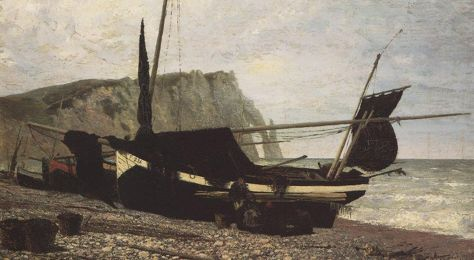

In [3]:
# (original, translation) pairs by Claude Opus 5.5, for reading only
TRANSLATIONS = dict(
    [
        (
            "ترسي تلك السفينه على اليابسه بعد ان انهكها البحر الشديد من السير فيه",
            "That ship has come to rest on dry land, worn out by sailing through the rough sea.",
        ),
        (
            "قارب متهالك لونه اسود يبدو وكأنه فقد صاحبه يتواجد علي شاطئ البحر",
            "A battered black boat on the seashore; it looks as if it has lost its owner.",
        ),
        (
            "海边的沙滩上搁浅着一艘破旧的船，看起来非常的唯美。",
            "A battered old boat lies stranded on the beach by the sea; it looks truly beautiful.",
        ),
        (
            "岸边破旧的船只，看着很萧条。",
            "A battered boat on the shore; it looks bleak.",
        ),
    ]
)

example = bal["painting"].sample(1, random_state=cfg.seed).iloc[0]
rows = bal[bal["painting"] == example].groupby("language").head(2)
rows = rows.set_index("language").loc[LANGS].reset_index()
show.show(
    show.figure(show.thumb(image_path(example), 260), show.title(example), width=380),
    show.annotation_table(rows, translations=TRANSLATIONS),
)

## 1. Do people disagree more across languages than within one?

**Hypothesis.** Two people writing in different languages disagree more about a
painting's emotion than two people writing in the same language.

**Method.**

- *Measure:* for each painting, draw small random groups of annotators from each
  language and compare the mix of emotions they chose. Comparing two groups from the
  same language gives disagreement *within* a language; comparing groups from two
  languages gives disagreement *across* languages. What we care about is the gap.
- *If language didn't matter:* shuffle the language tags within each painting and
  recompute the gap, many times.
- *Reading it:* supported if the real gap is clearly larger than the shuffled ones.

What this looks like on two paintings: the one where the languages disagree most, and
one where nearly everyone agrees. Compare how labels spread inside each language with
how they differ between languages.

● english,"contentment ×3, sadness ×2"
● arabic,amusement ×5
● chinese,contentment ×5
● english,"sadness ×4, disgust ×1"
● arabic,sadness ×5
● chinese,"sadness ×4, fear ×1"

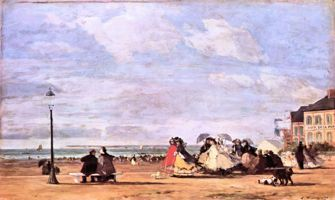
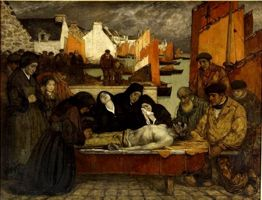

In [4]:
within, cross, pairs = analysis.split_half_divergence(
    labels, len(EMOS), cfg.analysis.n_bootstrap, cfg.seed
)
paintings = bal["painting"].unique()  # same order as `labels`
gap_by_painting = pd.Series(cross.mean(axis=1) - within.mean(axis=1), index=paintings)
top_share = pd.Series([np.bincount(lab.ravel()).max() for lab in labels], index=paintings)

examples = {
    "languages disagree most": gap_by_painting.idxmax(),
    "nearly everyone agrees": top_share.idxmax(),
}
show.show(
    *[
        show.figure(
            show.thumb(image_path(p), 200),
            f"<i>{note}</i><br>{show.title(p)}" + show.emotion_counts(bal, p, LANGS),
            width=420,
        )
        for note, p in examples.items()
    ]
)

First, each language's overall habits: how often it picks each emotion. All three
languages saw the same paintings, so any difference here comes from the annotators,
not from the paintings.

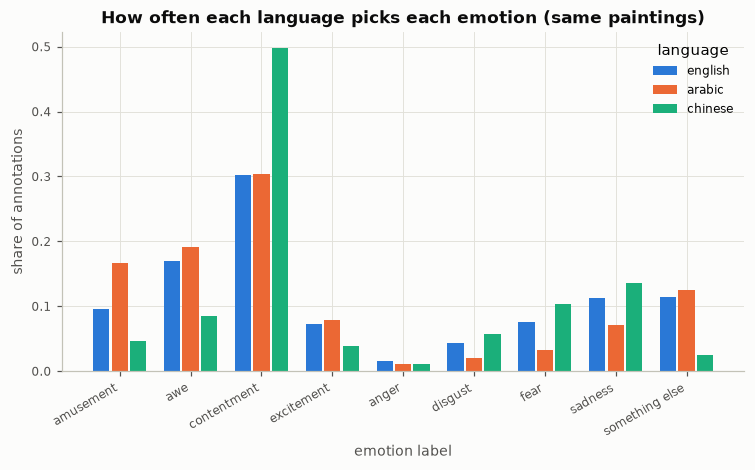

emotion,amusement,awe,contentment,excitement,anger,disgust,fear,sadness,something else
language,,,,,,,,,
english,0.095,0.170,0.303,0.072,0.015,0.044,0.076,0.112,0.114
arabic,0.166,0.191,0.304,0.079,0.010,0.020,0.033,0.071,0.125
chinese,0.046,0.085,0.497,0.039,0.012,0.057,0.103,0.136,0.025


In [5]:
priors = pd.crosstab(bal["emotion"], bal["language"], normalize="columns").loc[EMOS, LANGS]

fig, ax = plt.subplots(figsize=(8, 4))
x, w = np.arange(len(EMOS)), 0.26
for i, lang in enumerate(LANGS):
    ax.bar(x + (i - 1) * w, priors[lang], width=w - 0.03, color=plots.LANG_COLORS[lang], label=lang)
ax.set_xticks(x, EMOS, rotation=30, ha="right")
ax.set_ylabel("share of annotations")
ax.set_xlabel("emotion label")
ax.set_title("How often each language picks each emotion (same paintings)")
ax.legend(title="language")
plots.savefig(fig, "01_emotion_priors")
plt.show()
priors.T

Disagreement within and across languages, the gap between them, and the gaps we get
after shuffling.

In [6]:
gap_real = cross.mean() - within.mean()
gap_null = analysis.divergence_gap_null(
    labels, len(EMOS), cfg.analysis.n_permutations, cfg.analysis.n_bootstrap, cfg.seed
)
p_gap = analysis.permutation_p(gap_real, gap_null)

div_table = (
    pd.Series(
        {f"within {LANGS[i]}": within[:, i].mean() for i in range(len(LANGS))}
        | {f"cross {LANGS[i]}-{LANGS[j]}": cross[:, k].mean() for k, (i, j) in enumerate(pairs)}
    )
    .rename("mean JSD")
    .to_frame()
)
share_paintings = (cross.mean(axis=1) > within.mean(axis=1)).mean()
print(f"gap (cross - within): {gap_real:.3f}")
print(f"shuffled gaps: mean {gap_null.mean():.3f}, max {gap_null.max():.3f}; p = {p_gap:.3f}")
print(f"paintings where cross > within: {share_paintings:.0%}")
div_table

gap (cross - within): 0.081
shuffled gaps: mean -0.000, max 0.010; p = 0.005
paintings where cross > within: 70%


,mean JSD
within english,0.582
within arabic,0.610
within chinese,0.436
cross english-arabic,0.656
cross english-chinese,0.583
cross arabic-chinese,0.632


Left: average disagreement for each comparison. Right: the real gap against the
shuffled gaps.

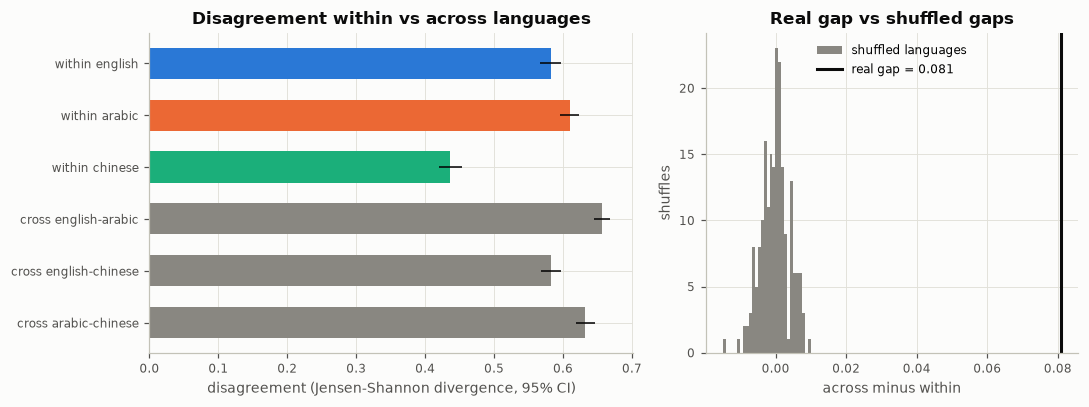

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})

names = list(div_table.index)
vals = div_table["mean JSD"].to_numpy()
per_painting = [within[:, i] for i in range(len(LANGS))] + [cross[:, k] for k in range(len(pairs))]
se = np.array([v.std(ddof=1) / np.sqrt(len(v)) for v in per_painting])
colors = [plots.LANG_COLORS[lang] for lang in LANGS] + [plots.NEUTRAL] * len(pairs)
ax1.barh(names, vals, xerr=1.96 * se, color=colors, height=0.6, error_kw={"lw": 1})
ax1.invert_yaxis()
ax1.set_xlabel("disagreement (Jensen-Shannon divergence, 95% CI)")
ax1.set_title("Disagreement within vs across languages")

ax2.hist(gap_null, bins=30, color=plots.NEUTRAL, label="shuffled languages")
ax2.axvline(gap_real, color=plots.INK, lw=2, label=f"real gap = {gap_real:.3f}")
ax2.set_xlabel("across minus within")
ax2.set_ylabel("shuffles")
ax2.set_title("Real gap vs shuffled gaps")
ax2.legend(loc="upper center")
fig.tight_layout()
plots.savefig(fig, "02_divergence_gap")
plt.show()

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported.</b> Two people writing in different languages disagree more about a
painting than two people writing in the same language. The gap is 0.081, while shuffled
languages never get past 0.010, and it shows up on 70% of paintings.

The languages also have visibly different habits. Chinese annotators pick contentment
about half the time and almost never "something else"; Arabic annotators lean more on
amusement and awe. Chinese annotators agree with each other the most.

</div>

## 2. Can we tell someone's language from the painting and the emotion they chose?

This turns the usual concept bottleneck around. Instead of predicting the emotion, we
predict the one thing in the data that is not a judgement: which language the
annotator wrote in.

**Hypothesis.** The emotion an annotator chose, alone or together with what is in the
painting, gives their language away.

**Method.**

- *Measure:* train a simple classifier (logistic regression) to predict language, and
  score it on paintings it has never seen. We try four kinds of input:
  - **concepts**: what is in the painting. CLIP scores how strongly the painting shows
    each of a list of plain visual concepts (a person, the sea, warm colours, visible
    brushstrokes…). Many concepts move together (a portrait scores high on "a face" and
    "a person" alike), so we summarise them into a handful of broad visual dimensions.
  - **emotion**: the label the annotator chose
  - **both**: concepts and emotion side by side
  - **interaction**: emotion combined with each visual dimension, such as "fear, on a
    painting with a lot of sea"
- *If language didn't matter:* shuffle the language tags within each painting and
  retrain, many times.
- *Reading it:* supported if the scores clearly beat their shuffled versions. Whether
  the painting adds anything beyond the emotion is the question of part 4.

Concepts alone cannot work here, by design: every language saw the same paintings
equally often. We keep that input as a check that nothing leaks, and it should land
exactly on chance. The concept list is deliberately generic, with no emotion words
and nothing culture-specific, which makes it a label-free starting point.

Embed the images and the concept descriptions with CLIP, and score every painting on
every concept.

In [8]:
clip = embed.load_clip(cfg.embedding.model, cfg.embedding.pretrained, DEVICE)
emb = cfg.embedding
img_cache = emb.cache_dir / f"images_{emb.model}_{emb.pretrained}.parquet"
img_emb = embed.embed_images(
    painting_images, cfg.data.images_dir, img_cache, clip, cfg.embedding.batch_size, DEVICE
)
concepts = [c for c in cfg.concepts.path.read_text().splitlines() if c.strip()]
txt_emb = embed.embed_texts([cfg.concepts.template.format(c) for c in concepts], clip, DEVICE)
scores = embed.concept_scores(img_emb, txt_emb, concepts)
image_to_painting = dict(zip(painting_images.to_numpy(), painting_images.index, strict=True))
scores.index = scores.index.map(image_to_painting)
print(f"{len(concepts)} concepts scored on {len(scores)} paintings")

152 concepts scored on 840 paintings


Do the concept scores make sense? Three random paintings with their five
highest-scoring concepts.


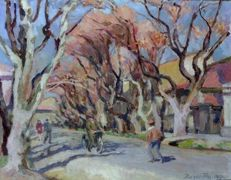
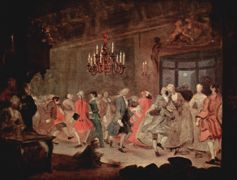
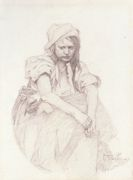

In [9]:
picks = pd.Series(scores.index).sample(3, random_state=cfg.seed)
show.show(
    *[
        show.figure(
            show.thumb(image_path(p), 180),
            f"<b>{show.title(p)}</b><br>" + ", ".join(scores.loc[p].nlargest(5).index),
            width=280,
        )
        for p in picks
    ]
)

Summarise the concept scores into broad visual dimensions. Each row shows the concepts
at the two ends of one dimension, which is how to read the dimension names (D1, D2, …)
in the rest of the notebook.

In [10]:
components, loadings = analysis.concept_components(
    scores, cfg.analysis.n_concept_components, cfg.seed
)
pd.set_option("display.max_colwidth", 90)
analysis.describe_components(loadings)

,high,low
D1,"low contrast, thin washes of colour, an asymmetrical composition, a bottle","a face, dots of paint, a line drawing, a dress"
D2,"a person, a portrait composition, a face, a book","a valley, a landscape composition, a hill, a lake"
D3,"empty space, dots of paint, organic shapes, curved lines","a market, daytime scene, a group of people, a wide panoramic view"
D4,"geometric shapes, a symmetrical composition, a crowded scene, a market","a face, green, pink, a person"
D5,"a ship, the sea, the moon, an island","saturated colours, warm colours, a street, cool colours"
D6,"a forest, a meadow, a tree, grass","a harbour, a city, a building, sunset light"
D7,"a sketch, a line drawing, grey, monochrome palette","gold, cool colours, geometric shapes, a symmetrical composition"
D8,"dim light, candlelight, loose rough handling, an abstract composition","dots of paint, a line drawing, fine detail, a grid pattern"
D9,"ice, dots of paint, flowers, snow","vertical lines, a symmetrical composition, a realistic depiction, strong perspective d..."
D10,"a boat, a harbour, curved lines, a beach","silver, dim light, backlighting, a forest"


One dimension in pictures: the paintings at the high end (top row) and the low end
(bottom row) of D2.


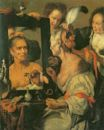
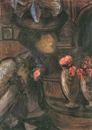
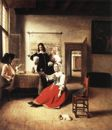
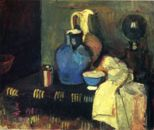
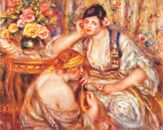


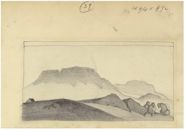
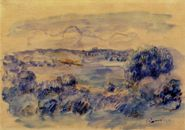
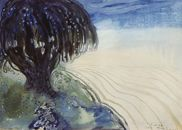
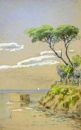
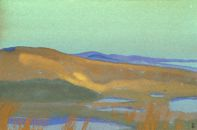

In [11]:
dim = "D2"
for end, idx in [
    ("high", components[dim].nlargest(5).index),
    ("low", components[dim].nsmallest(5).index),
]:
    show.show(*[show.figure(show.thumb(image_path(p), 130), f"{end} {dim}") for p in idx])

What the classifier actually gets for one annotation: the emotion that was chosen and
where the painting sits on each visual dimension. From that, it has to guess the
language.


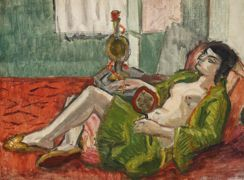

In [12]:
ex = bal.sample(1, random_state=cfg.seed + 1).iloc[0]
dims = ", ".join(f"{d} {v:+.1f}" for d, v in components.loc[ex["painting"]].items())
show.show(
    show.figure(show.thumb(image_path(ex["painting"]), 180), show.title(ex["painting"]), width=280),
    f"<div style='max-width:440px'><b>emotion:</b> {ex['emotion']}<br>"
    f"<b>visual dimensions:</b> {dims}<br><br>"
    f"<b>which language?</b> Answer: {show.lang_label(ex['language'])}</div>",
)

Train and score the classifier on each kind of input, with its shuffled baseline.

In [13]:
FEATURE_SETS = ["concepts", "emotion", "both", "interaction"]
y, groups = bal["language"].to_numpy(), bal["painting"].to_numpy()

rows, cbm_nulls = [], {}
for kind in FEATURE_SETS:
    X, _ = analysis.make_features(bal, kind, EMOS, components)
    real = analysis.cv_balanced_accuracy(
        X, y, groups, cfg.analysis.cv_folds, cfg.analysis.logreg_C, cfg.seed
    )
    row = {"input": kind, "n features": X.shape[1], "balanced acc": real}
    if kind != "concepts":  # exactly chance by construction; shuffling adds nothing
        cbm_nulls[kind] = analysis.permutation_null(
            X,
            y,
            groups,
            cfg.analysis.n_permutations,
            cfg.analysis.cv_folds,
            cfg.analysis.logreg_C,
            cfg.seed,
        )
        row |= {
            "shuffled mean": cbm_nulls[kind].mean(),
            "shuffled max": cbm_nulls[kind].max(),
            "p": analysis.permutation_p(real, cbm_nulls[kind]),
        }
    rows.append(row)
cbm = pd.DataFrame(rows).set_index("input")
print("chance (always guessing one language): 0.333")
cbm

chance (always guessing one language): 0.333


,n features,balanced acc,shuffled mean,shuffled max,p
input,,,,,
concepts,10,0.333,NaN,NaN,NaN
emotion,9,0.457,0.333,0.347,0.005
both,19,0.455,0.333,0.347,0.005
interaction,99,0.464,0.333,0.345,0.005


Real scores against the range of shuffled scores and chance.

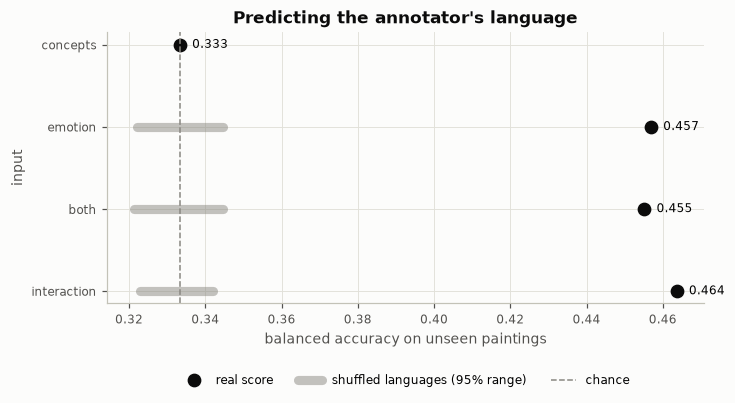

In [14]:
def plot_cbm(table, nulls, title, ax):
    for i, kind in enumerate(table.index):
        if kind in nulls:
            lo, hi = np.quantile(nulls[kind], [0.025, 0.975])
            ax.plot(
                [lo, hi],
                [i, i],
                color=plots.NEUTRAL,
                lw=6,
                alpha=0.5,
                solid_capstyle="round",
                label="shuffled languages (95% range)" if i == 1 else None,
            )
        ax.plot(
            table.loc[kind, "balanced acc"],
            i,
            "o",
            color=plots.INK,
            ms=8,
            label="real score" if i == 0 else None,
        )
        ax.annotate(
            f"{table.loc[kind, 'balanced acc']:.3f}",
            (table.loc[kind, "balanced acc"], i),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            fontsize=8,
        )
    ax.axvline(1 / 3, color=plots.NEUTRAL, ls="--", lw=1, label="chance")
    ax.set_yticks(range(len(table)), table.index)
    ax.invert_yaxis()
    ax.set_xlabel("balanced accuracy on unseen paintings")
    ax.set_ylabel("input")
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)


fig, ax = plt.subplots(figsize=(7, 3.2))
plot_cbm(cbm, cbm_nulls, "Predicting the annotator's language", ax)
plots.savefig(fig, "03_inverted_cbm")
plt.show()

What the model leans on: for each language, the combinations of visual dimension and
emotion that push its prediction toward that language the most (read the dimensions
with the table above). These describe this model on this sample. They are not facts
about cultures.

In [15]:
X_int, int_names = analysis.make_features(bal, "interaction", EMOS, components)
model = analysis.logreg(cfg.analysis.logreg_C).fit(X_int, y)
coef = pd.DataFrame(model[-1].coef_, index=model[-1].classes_, columns=int_names)
coef = coef.loc[:, [n for n in int_names if " | " in n]]  # concept x emotion terms only
top = pd.DataFrame({lang: coef.loc[lang].nlargest(8).index for lang in LANGS})
top.index = range(1, 9)
top

,english,arabic,chinese
1,D2 | amusement,D1 | amusement,D2 | amusement
2,D1 | anger,D2 | sadness,D3 | awe
3,D1 | contentment,D2 | contentment,D5 | amusement
4,D3 | excitement,D5 | excitement,D3 | amusement
5,D2 | awe,D9 | amusement,D7 | amusement
6,D4 | something else,D8 | sadness,D4 | awe
7,D3 | amusement,D7 | awe,D4 | amusement
8,D8 | excitement,D8 | awe,D10 | amusement


<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported.</b> The chosen emotion alone guesses the annotator's language at 0.457,
against 0.333 for chance and at most 0.347 for shuffled languages. Adding what is in the
painting barely moves it (0.464 for the interaction). Concepts alone sit exactly on
chance, as they should, so nothing leaks.

</div>

## 3. How much of an emotion choice comes from the painting, and how much from the language?

**Hypothesis.** Language accounts for a real share of which emotion people pick. It
does so on its own, and in combination with the painting, when the same painting is
read differently in different languages.

**Method.**

- *Measure:* split the variation in emotion choice into four parts: the painting, the
  language, painting × language, and what is left over (a two-way analysis of
  variance, with each emotion coded as a yes/no choice).
- *If language didn't matter:* shuffle the language tags within each painting and
  recompute the language and painting × language shares, many times.
- *Reading it:* supported if both shares exceed their shuffled versions. Their size
  next to the painting share tells us how much language matters compared with the
  painting itself.

The three parts on three paintings: one where the painting decides (almost everyone
picks the same emotion), one where the languages split the most, and a typical one.

● english,contentment ×5
● arabic,"contentment ×3, amusement ×2"
● chinese,contentment ×5
● english,"awe ×4, fear ×1"
● arabic,"excitement ×3, sadness ×1, something else ×1"
● chinese,"contentment ×4, fear ×1"
● english,"contentment ×2, fear ×1, something else ×1, excitement ×1"
● arabic,"excitement ×2, awe ×1, contentment ×1, something else ×1"
● chinese,contentment ×5

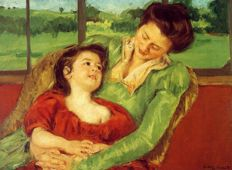
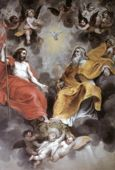
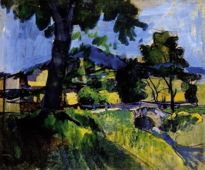

In [16]:
onehot = pd.get_dummies(bal["emotion"]).astype(float)
onehot[["painting", "language"]] = bal[["painting", "language"]]
cell = onehot.groupby(["painting", "language"]).mean()
by_painting = cell.groupby(level="painting").mean()
by_language = cell.groupby(level="language").mean()
interaction = (
    cell
    - by_painting.reindex(cell.index, level="painting").to_numpy()
    - by_language.reindex(cell.index, level="language").to_numpy()
    + cell.mean()
)
split = (interaction**2).sum(axis=1).groupby(level="painting").sum()

examples = {
    "the painting decides": top_share.nlargest(2).index[1],
    "the languages split": split.drop(gap_by_painting.idxmax()).idxmax(),
    "a typical painting": (split - split.median()).abs().idxmin(),
}
show.show(
    *[
        show.figure(
            show.thumb(image_path(p), 170),
            f"<i>{note}</i><br>{show.title(p)}" + show.emotion_counts(bal, p, LANGS),
            width=340,
        )
        for note, p in examples.items()
    ]
)

The four shares for each emotion and summed over all emotions, and the shuffled
baseline.

In [17]:
vs = analysis.variance_split(bal, EMOS)

rng = np.random.default_rng(cfg.seed)
null_rows = []
for _ in range(cfg.analysis.n_permutations):
    shuffled_lang = analysis.shuffle_labels_within(
        bal["language"].to_numpy(), bal["painting"].to_numpy(), rng
    )
    shuffled = bal.assign(language=shuffled_lang)
    null_rows.append(analysis.variance_split(shuffled, EMOS).loc["all emotions"])
vs_null = pd.DataFrame(null_rows)

real = vs.loc["all emotions"]
for term in ["language", "interaction"]:
    print(
        f"{term:12s} share {real[term]:.3f} | shuffled mean {vs_null[term].mean():.3f}, "
        f"max {vs_null[term].max():.3f} | p = "
        f"{analysis.permutation_p(real[term], vs_null[term].to_numpy()):.3f}"
    )
vs

language     share 0.021 | shuffled mean 0.000, max 0.000 | p = 0.005
interaction  share 0.142 | shuffled mean 0.122, max 0.126 | p = 0.005


,painting,language,interaction,residual,noise_floor
amusement,0.097,2.639e-02,0.177,0.699,0.116
awe,0.103,1.673e-02,0.148,0.733,0.122
contentment,0.163,3.594e-02,0.142,0.659,0.110
excitement,0.098,5.294e-03,0.131,0.766,0.127
anger,0.077,3.276e-04,0.144,0.779,0.130
disgust,0.124,5.913e-03,0.140,0.731,0.122
fear,0.208,1.291e-02,0.129,0.651,0.108
sadness,0.240,7.571e-03,0.119,0.633,0.105
something else,0.092,2.483e-02,0.136,0.747,0.124
all emotions,0.144,2.120e-02,0.142,0.693,0.115


The shares for each emotion. The black tick shows how large the painting × language
part would be from noise alone.

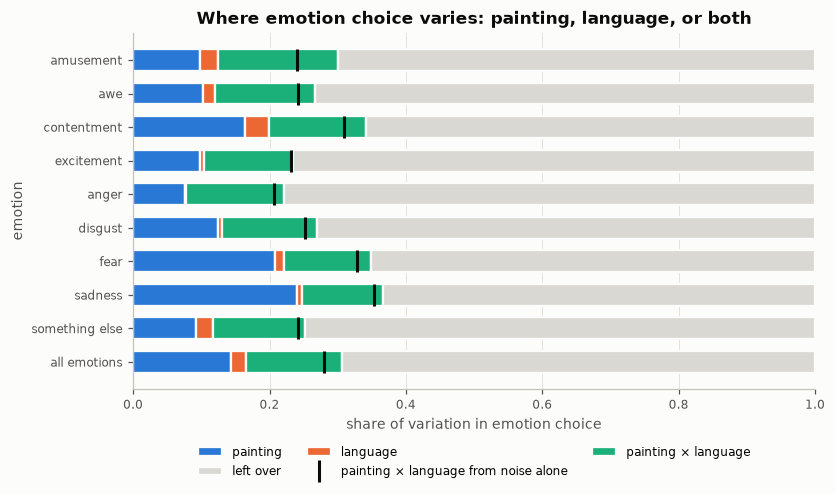

In [18]:
terms = ["painting", "language", "interaction", "residual"]
term_colors = {
    "painting": "#2a78d6",
    "language": "#eb6834",
    "interaction": "#1baf7a",
    "residual": "#d9d8d2",
}
term_labels = {
    "painting": "painting",
    "language": "language",
    "interaction": "painting × language",
    "residual": "left over",
}
fig, ax = plt.subplots(figsize=(8, 4.2))
left = np.zeros(len(vs))
for term in terms:
    ax.barh(
        vs.index,
        vs[term],
        left=left,
        color=term_colors[term],
        height=0.65,
        edgecolor="#fcfcfb",
        linewidth=1.5,
        label=term_labels[term],
    )
    left += vs[term].to_numpy()
floor_x = vs["painting"] + vs["language"] + vs["noise_floor"]
ax.plot(
    floor_x,
    range(len(vs)),
    "|",
    color=plots.INK,
    ms=14,
    mew=2,
    label="painting × language from noise alone",
)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of variation in emotion choice")
ax.set_ylabel("emotion")
ax.set_title("Where emotion choice varies: painting, language, or both")
handles, names = ax.get_legend_handles_labels()
order = [
    names.index(n)
    for n in [
        "painting",
        "left over",
        "language",
        "painting × language from noise alone",
        "painting × language",
    ]
]
ax.legend(
    [handles[i] for i in order],
    [names[i] for i in order],
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
)
plots.savefig(fig, "04_variance_split")
plt.show()

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported, but language is a small part.</b> The painting explains about 14% of the
variation in which emotion people pick; language on its own about 2%. Painting ×
language comes out at 14%, but shuffled languages already give about 12%, so only
about two points of it are real. Most of the variation (about 69%) is left over:
differences between individual annotators and noise, which we cannot tell apart.

</div>

## 4. Does what is in the painting add anything beyond label habits?

Part 1 showed that each language favours some emotions over others. The emotion-only
classifier in part 2 already knows these habits completely: if one language picks
contentment more often, it guesses that language from contentment. So the real question
is whether knowing what is in the painting adds anything on top.

**Hypothesis.** Painting content improves the language guess beyond what the chosen
emotion alone gives: languages attach different emotions to the same visual content.

**Method.**

- *Measure:* the score of the interaction classifier from part 2 (emotion combined with
  the visual dimensions).
- *If painting content didn't matter:* keep every annotation's language and emotion as
  they are, but give each painting the visual profile of a random other painting, and
  retrain, many times. Label habits stay intact; only the link to what is actually in
  the painting is broken.
- *Reading it:* supported if the real score beats every swapped score.

The swap on one annotation: the real pairing, and the same annotation after it has been
handed a random other painting's visual profile.


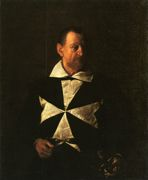
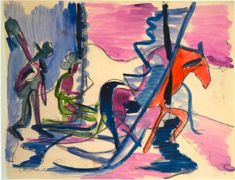

In [19]:
ex = bal.sample(1, random_state=cfg.seed + 2).iloc[0]
other = pd.Series(components.index).sample(1, random_state=cfg.seed + 3).iloc[0]
who = f"{show.lang_label(ex['language'])} annotator chose <b>{ex['emotion']}</b>"
show.show(
    show.figure(
        show.thumb(image_path(ex["painting"]), 180),
        f"<b>real:</b> {who}<br>for this painting",
        width=300,
    ),
    "<div style='font-size:2em;padding-top:70px'>→</div>",
    show.figure(
        show.thumb(image_path(other), 180),
        "<b>swapped:</b> same annotator and label, now paired with this painting's visual profile",
        width=300,
    ),
)

Score the interaction classifier with swapped visual profiles, and compare.

In [20]:
swap_null = analysis.concept_swap_null(
    bal,
    EMOS,
    components,
    cfg.analysis.n_permutations,
    cfg.analysis.cv_folds,
    cfg.analysis.logreg_C,
    cfg.seed,
)
real_int, emo_only = cbm.loc["interaction", "balanced acc"], cbm.loc["emotion", "balanced acc"]
p_swap = analysis.permutation_p(real_int, swap_null)
print(f"interaction, real paintings:     {real_int:.3f}")
print(
    f"interaction, swapped paintings:  mean {swap_null.mean():.3f}, max {swap_null.max():.3f}"
    f"; p = {p_swap:.3f}"
)
print(f"emotion alone (for reference):   {emo_only:.3f}")

interaction, real paintings:     0.464
interaction, swapped paintings:  mean 0.447, max 0.453; p = 0.005
emotion alone (for reference):   0.457


The real score against the swapped scores, with emotion alone for reference.

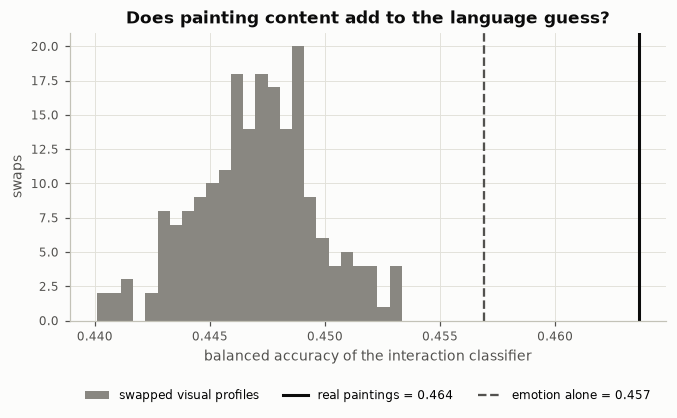

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(swap_null, bins=25, color=plots.NEUTRAL, label="swapped visual profiles")
ax.axvline(real_int, color=plots.INK, lw=2, label=f"real paintings = {real_int:.3f}")
ax.axvline(emo_only, color=plots.INK_2, lw=1.5, ls="--", label=f"emotion alone = {emo_only:.3f}")
ax.set_xlabel("balanced accuracy of the interaction classifier")
ax.set_ylabel("swaps")
ax.set_title("Does painting content add to the language guess?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plots.savefig(fig, "05_concept_swap")
plt.show()

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported, but small.</b> The real paintings beat every swapped version (0.464
against at most 0.453), so what is in the painting does carry some language signal
beyond label habits. The gain over the emotion alone is less than one point of
accuracy.

</div>

## What we found

- **People disagree more across languages than within one (part 1: supported).** The
  gap is far outside anything the shuffled languages produce, and holds for about
  seven in ten paintings. Chinese annotators agree with each other the most.
- **Each language has its own label habits (parts 1 and 2: supported).** On the same
  paintings, Chinese annotators pick contentment about half the time and rarely use
  "something else"; Arabic annotators pick amusement and awe more often. The emotion
  alone is enough to guess the language well above chance (0.46 against 0.33).
- **What is in the painting adds only a little (part 4: supported, but small).**
  Combining the emotion with the painting's visual dimensions beats every swapped
  version, but it moves the guess from 0.457 to 0.464.
- **The painting matters far more than the language (part 3).** The painting explains
  about 14% of the variation in emotion choice and language on its own about 2%.
  Painting × language looks as large as the painting, but most of it is noise: only a
  couple of percentage points sit above what shuffled languages give.

Taken together: the language differences are real, but they live mostly in how often
each language uses each label. The part tied to what is in the painting, which is the
part a concept bottleneck could explain, is small. All of this is subject to the
caveats below, especially the unequal annotator pools.

## Caveats

- **No annotator IDs.** The left-over variation mixes individual differences with
  noise, so nothing here says anything about individuals versus groups.
- **Unequal annotator pools.** The original ArtELingo had about 6,377 English, 656
  Arabic and 745 Chinese workers, so each Arabic or Chinese worker labelled many more
  paintings. We have not yet checked that the rows used here come from the same pools.
  Either way, "language" may partly mean "a few prolific annotators".
- **Small groups.** Part 1 compares very small groups of annotators, which makes the
  disagreement numbers high in absolute terms; only the gap means something. For the
  same reason, part of the painting × language share in part 3 is noise (the tick in
  the figure).
- **One encoder, one vocabulary.** The concept scores come from one CLIP model and one
  generic concept list. Another encoder or vocabulary could change parts 2 and 4.
- **Broad dimensions, not single concepts.** The classifiers see a handful of visual
  dimensions rather than individual concepts. The first dimension carries most of the
  variation and has no obvious meaning.
- **An earlier version of part 4 did not work.** Reweighting labels to give every
  language the same emotion mix brought back imbalance within paintings, so we switched
  to the swap test.
- **Model settings.** The classifier's settings were fixed before we looked at real
  results, and the baselines use the same ones. Other settings might shift the
  interaction score.

## Next steps

- **Other concept vocabularies:** translated and native ones, built so they cannot leak
  the emotion label.
- **Another encoder:** a multilingual CLIP, to see how much depends on the encoder.
- **Sham interventions:** compare real concept interventions with random ones.
- **"Something else":** what lands in this catch-all label in each language.
- **Styles,** and a VisDiff-style comparison of concept differences.
- **Annotator pools:** confirm where the English, Arabic and Chinese rows come from, and
  whether the other 25 languages in ArtELingo-28 are usable for the same questions.